# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [4]:
df = pd.read_csv("Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [5]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [6]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [7]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

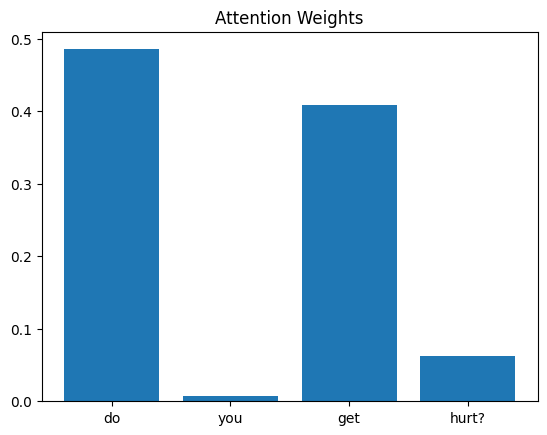

In [8]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question 1: Highest attention = do
Question 2: Highest attention = do
Question 3: Highest attention = do


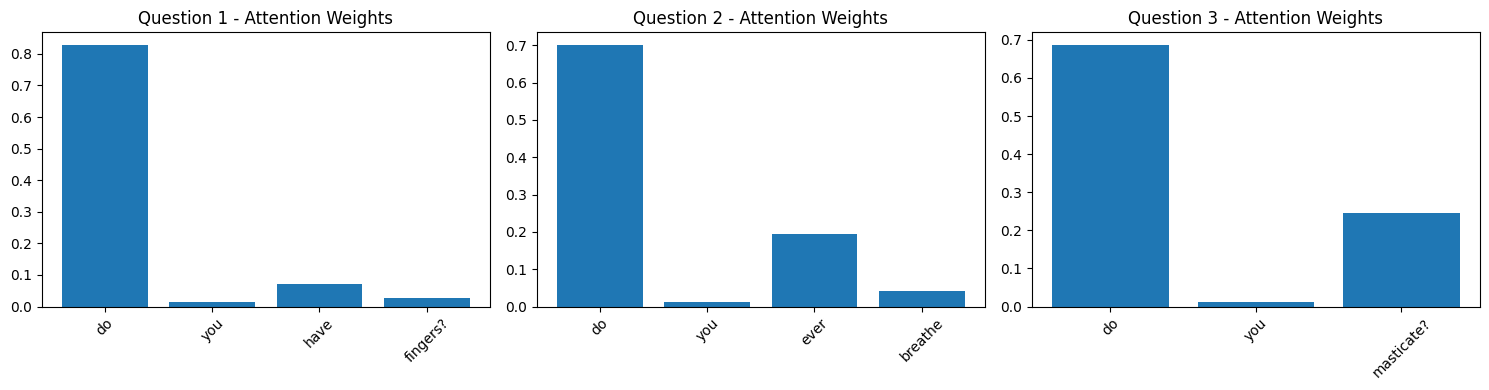

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i in range(1, 4):
    question = df["question"][i]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    axes[i-1].bar(words, weights[0, :len(words)].tolist())
    axes[i-1].set_title(f"Question {i} - Attention Weights")
    axes[i-1].tick_params(axis='x', rotation=45)

    highest_idx = weights[0, :len(words)].argmax().item()
    print(f"Question {i}: Highest attention = {words[highest_idx]}")

plt.tight_layout()
plt.show()

The word do received the highest attention weight in all three questions. However, it is not the most informative word for understanding their meaning. Words such as fingers, breathe, and masticate provide more specific information about each question. This suggests that the model focuses heavily on the beginning of the questions rather than always assigning the highest attention to the most meaningful words.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question 46: Highest attention = built
Question 48: Highest attention = who


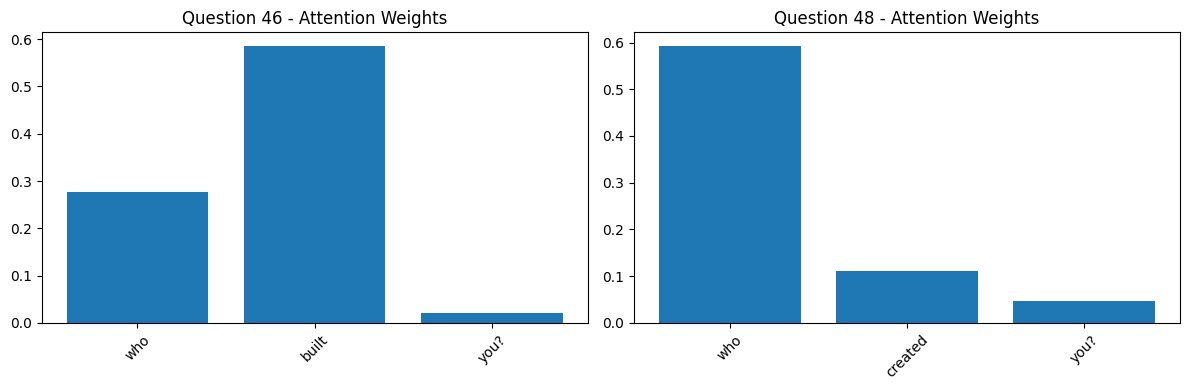

In [13]:
indices = [46, 48]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for j, i in enumerate(indices):
    question = df["question"][i]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    axes[j].bar(words, weights[0, :len(words)].tolist())
    axes[j].set_title(f"Question {i} - Attention Weights")
    axes[j].tick_params(axis='x', rotation=45)

    highest_idx = weights[0, :len(words)].argmax().item()
    print(f"Question {i}: Highest attention = {words[highest_idx]}")

plt.tight_layout()
plt.show()

The model focuses on different words even though both questions have similar meanings. In Who built you?, the word built receives the highest attention weight, while in Who created you?, the word who receives the highest attention weight. This suggests that attention weights depend on the wording and context of each question, not only its overall meaning. Therefore, similar questions do not necessarily produce the same attention distribution.